# Практическая работа по Уроку 3: Feature Engineering и предобработка данных
## Анализ 1-комнатных квартир в г. Астана (районы Есиль и Нура, постройка с 2016 г., объявления за 2026 год)

### Постановка задачи
В рамках выполнения практического задания согласно **Уроку 3 («Предобработка данных и Feature Engineering»)** проводится комплексное исследование объявлений о продаже недвижимости на платформе **Krisha.kz**:
- **Город**: Астана
- **Районы**: Есильский р-н и Нура р-н
- **Комнатность**: строго 1-комнатные квартиры
- **Год постройки дома**: начиная с 2016 года по 2026 год (`construction_year >= 2016`)
- **Период объявлений**: начиная с января 2026 года (`Date >= 2026-01-01`)

### Основные этапы согласно программе Урока 3:
1. **01 — Первичный осмотр и очистка данных**: поиск дубликатов, реализация функции удаления столбцов `delete_columns` (Задание 2).
2. **02 — Feature Engineering (операции со столбцами)**:
   - Векторный расчет квадрата цены `price_square` (Задание 1).
   - Расчет цены за квадратный метр (`Price_m2`).
   - Анализ этажности: коэффициент этажа `FloorRatio` и признак `FloorType` (первый / средний / последний).
3. **03 — Работа с датой и временем (datetime)**:
   - Приведение к `datetime64`, выделение года, месяца (`MonthSale`), дня недели (`WeekdaySale`).
   - Расчет возраста здания `AgeBuilding = YearSale - construction_year`.
   - Функция `get_weekend` и создание признака `Weekend` (Задание 4 и 7).
   - Сравнение цен в выходные дни и будни.
4. **04 — Категориальные признаки и тип `category`**:
   - Таблица уникальности `unique_counts` (`nunique()`, `dtypes`).
   - Оптимизация памяти через приведение подходящих столбцов к `category` (Задание 6).
   - Оптимизация редких категорий: топ популярных ЖК и продавцов против `'other'` (Задание 6 и 8).
5. **05 — Сравнительный анализ районов Есиль и Нура**:
   - Сравнение средних и медианных цен и цены за м².
   - Распределение по типам домов (монолит vs кирпич vs панель).
   - Динамика цен по годам постройки и месяцам 2026 года.
   - Топ-10 жилых комплексов по привлекательности цены.

   fghfghgf


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка визуализации
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', palette='muted')

print('Библиотеки успешно импортированы!')


Библиотеки успешно импортированы!


## 01 — Загрузка данных и первичное исследование
Загружаем сформированный датасет по г. Астана (`krisha_astana_esil_nura_2026.csv`), полученный на основе сбора данных из Krisha_Parser.
Оставляем исходную копию датасета нетронутой (согласно лайфхаку из урока 3).


In [2]:
# Загрузка датасета
krisha_data = pd.read_csv('krisha_astana_esil_nura_2026.csv')

# Создание рабочей копии таблицы
krisha_df = krisha_data.copy()

print(f"Размерность исходного датасета: {krisha_df.shape[0]} строк, {krisha_df.shape[1]} столбцов")
display(krisha_df.head(5))


Размерность исходного датасета: 750 строк, 19 столбцов


,city,name,district,address,price,price_text,price_is_from,owner,complex_name,house_type,construction_year,ceiling_height,bathroom_info,area,room_count,floor,floor_count,url,date
0,Астана,1-комнатная квартира · 42.78 м² · 8/21 этаж,Нура р-н,"Нура р-н, Бухар жырау 20",41838840,"41,838,840 ₸",True,Новостройка ЖК «Qasteev» от застройщика «BI Group Север»,Qasteev,NaN,2027,3 м,совмещенный,42.78,1,8,21,https://krisha.kz/a/show/1010216007,2026-11-23
1,Астана,1-комнатная квартира · 37.43 м² · 6/14 этаж,Есильский р-н,"Есильский р-н, Е 915 11 — Улы дала",26000000,"26,000,000 ₸",False,Крыша Агент,Jetisu Kerbez Comfort,монолитный,2026,3 м,совмещенный,37.43,1,6,14,https://krisha.kz/a/show/1017116184,2026-11-23
2,Астана,1-комнатная квартира · 38 м² · 3/9 этаж,Есильский р-н,"Есильский р-н, мкр Комсомольский, Улы Дала Е 908",19500000,"19,500,000 ₸",False,Хозяин недвижимости,Uly Dala Park,монолитный,2027,3 м,раздельный,38.00,1,3,9,https://krisha.kz/a/show/1017150440,2026-11-23
3,Астана,1-комнатная квартира · 42.54 м² · 17/17 этаж,Есильский р-н,"Есильский р-н, шоссе Каркаралы 4Б",25906860,"25,906,860 ₸",True,Новостройка ЖК «Impulse.Sport» от застройщика «BI Group Север»,Impulse.Sport,NaN,2027,3 м,совмещенный,42.54,1,17,17,https://krisha.kz/a/show/1017298496,2026-11-23
4,Астана,1-комнатная квартира · 39.18 м² · 8/9 этаж,Нура р-н,"Нура р-н, Е 882 13",24000000,"24,000,000 ₸",False,Крыша Агент,ABAI JOLY AVENUE,монолитный,2026,3 м,NaN,39.18,1,8,9,https://krisha.kz/a/show/1016288771,2026-11-23


### Проверка структуры и типов данных исходной таблицы


In [3]:
krisha_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   city               750 non-null    str    
 1   name               750 non-null    str    
 2   district           750 non-null    str    
 3   address            750 non-null    str    
 4   price              750 non-null    int64  
 5   price_text         750 non-null    str    
 6   price_is_from      750 non-null    bool   
 7   owner              750 non-null    str    
 8   complex_name       750 non-null    str    
 9   house_type         743 non-null    str    
 10  construction_year  750 non-null    int64  
 11  ceiling_height     750 non-null    str    
 12  bathroom_info      745 non-null    str    
 13  area               750 non-null    float64
 14  room_count         750 non-null    int64  
 15  floor              750 non-null    int64  
 16  floor_count        750 non-null    in

## 02 — Очистка данных и удаление лишних признаков

### Поиск и удаление дубликатов
Проверяем наличие дублирующихся объявлений по уникальному URL и ключевым параметрам.


In [4]:
# Проверка дубликатов по URL
dup_count = krisha_df.duplicated(subset=['url']).sum()
print(f"Количество полных дубликатов по URL: {dup_count}")

# Удаление дубликатов
krisha_df = krisha_df.drop_duplicates(subset=['url']).reset_index(drop=True)
print(f"Строк после удаления дубликатов: {krisha_df.shape[0]}")


Количество полных дубликатов по URL: 0
Строк после удаления дубликатов: 750


### Задание 2 из Урока 3: реализация функции `delete_columns`
Напишем функцию `delete_columns(df, col=[])`, которая:
- принимает DataFrame и список названий столбцов;
- удаляет указанные столбцы и возвращает новый DataFrame;
- если хотя бы одного столбца нет в таблице — возвращает `None`.

Удалим неинформативные признаки: `['url', 'price_text', 'price_is_from', 'room_count', 'city']` (город и комнатность константны: Астана, 1 комната).


In [5]:
def delete_columns(df, col=[]):
    '''
    Удаляет указанные столбцы из таблицы.
    Если хотя бы один столбец отсутствует, возвращает None.
    '''
    for c in col:
        if c not in df.columns:
            return None
    return df.drop(col, axis=1)

cols_to_remove = ['url', 'price_text', 'price_is_from', 'room_count', 'city']
krisha_df = delete_columns(krisha_df, cols_to_remove)

print("Столбцы после удаления:")
print(krisha_df.columns.tolist())


Столбцы после удаления:
['name', 'district', 'address', 'price', 'owner', 'complex_name', 'house_type', 'construction_year', 'ceiling_height', 'bathroom_info', 'area', 'floor', 'floor_count', 'date']


## 03 — Feature Engineering: математические операции со столбцами

### Задание 1 из Урока 3: Квадрат цены (`price_square`)
Векторно вычисляем квадрат цены для каждого объекта и сохраняем в Series `price_square`.


In [6]:
# Векторное вычисление квадрата цены (Задание 1)
price_square = krisha_df['price'] ** 2
display(price_square.head())


0    1750488532545600
1     676000000000000
2     380250000000000
3     671165395059600
4     576000000000000


### Создание новых признаков:
1. **`Price_m2`** — стоимость 1 квадратного метра: `price / area`, округленная до целых.
2. **`FloorRatio`** — относительное положение этажа в здании: `floor / floor_count`.
3. **`FloorType`** — категория этажа: `'первый'`, `'последний'`, `'средний'`.


In [7]:
# 1. Стоимость одного квадратного метра
krisha_df['Price_m2'] = (krisha_df['price'] / krisha_df['area']).round().astype(int)

# 2. Отношение этажа к этажности дома
krisha_df['FloorRatio'] = (krisha_df['floor'] / krisha_df['floor_count']).round(2)

# 3. Категория этажа (первый, последний, средний)
def get_floor_type(row):
    if row['floor'] == 1:
        return 'первый'
    elif row['floor'] == row['floor_count']:
        return 'последний'
    else:
        return 'средний'

krisha_df['FloorType'] = krisha_df.apply(get_floor_type, axis=1)

display(krisha_df[['price', 'area', 'Price_m2', 'floor', 'floor_count', 'FloorRatio', 'FloorType']].head(5))


,price,area,Price_m2,floor,floor_count,FloorRatio,FloorType
0,41838840,42.78,978000,8,21,0.38,средний
1,26000000,37.43,694630,6,14,0.43,средний
2,19500000,38.00,513158,3,9,0.33,средний
3,25906860,42.54,609000,17,17,1.00,последний
4,24000000,39.18,612557,8,9,0.89,средний


### Сравнение цен по типам этажей (первый vs средний vs последний)


In [8]:
floor_price_stats = krisha_df.groupby('FloorType').agg(
    count=('price', 'count'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median'),
    mean_price_m2=('Price_m2', 'mean')
).round(0)
display(floor_price_stats)


,count,mean_price,median_price,mean_price_m2
FloorType,,,,
первый,51,27531373.0,27200000.0,695364.0
последний,59,30076387.0,29600000.0,703404.0
средний,640,30405135.0,30150000.0,726470.0


## 04 — Работа с датой и временем (datetime)

### Преобразование столбца `date` в формат datetime
Извлекаем временные характеристики:
- `YearSale` — год размещения;
- `MonthSale` — месяц размещения (с 1 по 11);
- `WeekdaySale` — день недели (0 — понедельник, ..., 6 — воскресенье);
- `DayName` — название дня недели.
- **`AgeBuilding`** — возраст здания на момент публикации объявления: `YearSale - construction_year` (в точности как в Уроке 3: `AgeBuilding = Date.dt.year - YearBuilt`).


In [9]:
# Преобразование к datetime
krisha_df['date'] = pd.to_datetime(krisha_df['date'])

# Извлечение компонентов даты
krisha_df['YearSale'] = krisha_df['date'].dt.year
krisha_df['MonthSale'] = krisha_df['date'].dt.month
krisha_df['WeekdaySale'] = krisha_df['date'].dt.day_of_week
krisha_df['DayName'] = krisha_df['date'].dt.day_name()

# Возраст здания на момент публикации
krisha_df['AgeBuilding'] = krisha_df['date'].dt.year - krisha_df['construction_year']

print("Диапазон дат объявлений:", krisha_df['date'].min().date(), "—", krisha_df['date'].max().date())
display(krisha_df[['date', 'MonthSale', 'WeekdaySale', 'DayName', 'construction_year', 'AgeBuilding']].head())


Диапазон дат объявлений: 2026-01-05 — 2026-11-23


,date,MonthSale,WeekdaySale,DayName,construction_year,AgeBuilding
0,2026-11-23,11,0,Monday,2027,-1
1,2026-11-23,11,0,Monday,2026,0
2,2026-11-23,11,0,Monday,2027,-1
3,2026-11-23,11,0,Monday,2027,-1
4,2026-11-23,11,0,Monday,2026,0


### Задания 4 и 7 из Урока 3: функция `get_weekend` и средняя цена
1. Реализуем функцию `get_weekend(weekday: int) -> int`, которая возвращает 1, если день недели — суббота (5) или воскресенье (6), иначе 0.
2. Создаем столбец `Weekend` с помощью этой функции через метод `.apply()`.
3. Считаем `weekend_count` — количество объектов, выставленных на продажу в выходные.
4. Вычисляем и сравниваем среднюю цену объектов, проданных/выставленных в выходные дни и в будни.


In [10]:
# Реализация функции get_weekend (Задание 7)
def get_weekend(weekday: int) -> int:
    '''Возвращает 1 для субботы (5) и воскресенья (6), иначе 0'''
    return 1 if weekday in (5, 6) else 0

krisha_df['Weekend'] = krisha_df['WeekdaySale'].apply(get_weekend)

# Подсчет количества объявлений в выходные (Задание 4)
weekend_count = (krisha_df['Weekend'] == 1).sum()
print(f"Количество объявлений, размещенных в выходные дни (weekend_count): {weekend_count}")

# Средняя цена в выходные и будни
weekend_mean_price = krisha_df[krisha_df['Weekend'] == 1]['price'].mean()
weekday_mean_price = krisha_df[krisha_df['Weekend'] == 0]['price'].mean()

print(f"Средняя цена в выходные дни: {round(weekend_mean_price):,} тг".replace(',', ' '))
print(f"Средняя цена в будние дни:  {round(weekday_mean_price):,} тг".replace(',', ' '))
print(f"Разница: {round(weekend_mean_price - weekday_mean_price):,} тг".replace(',', ' '))


Количество объявлений  размещенных в выходные дни (weekend_count): 219
Средняя цена в выходные дни: 29 948 858 тг
Средняя цена в будние дни:  30 280 778 тг
Разница: -331 920 тг


## 05 — Категориальные признаки и тип `category`

### Анализ уникальности признаков (`unique_counts`)
Составим таблицу `unique_counts`, где для каждого признака посчитаем:
- название столбца;
- количество уникальных значений (`nunique()`);
- тип данных (`dtypes`).


In [11]:
unique_list = []
for col in krisha_df.columns:
    item = (col, krisha_df[col].nunique(), str(krisha_df[col].dtypes))
    unique_list.append(item)

unique_counts = pd.DataFrame(unique_list, columns=['Признак', 'Уникальных_значений', 'Тип_данных']).sort_values('Уникальных_значений')
display(unique_counts)


,Признак,Уникальных_значений,Тип_данных
17,YearSale,1,int32
22,Weekend,2,int64
1,district,2,str
9,bathroom_info,2,str
6,house_type,3,str
16,FloorType,3,str
8,ceiling_height,5,str
20,DayName,7,str
19,WeekdaySale,7,int32
18,MonthSale,11,int32


### Задание 6 из Урока 3: Оптимизация памяти через приведение к `category`
1. Измеряем объем памяти таблицы до преобразования (`memory_usage(deep=True)`).
2. Выбираем признаки, число уникальных значений которых меньше 150 (`district`, `house_type`, `ceiling_height`, `bathroom_info`, `owner`, `FloorType`).
3. Приводим их к типу `category`.
4. Измеряем объем памяти после преобразования и вычисляем процент экономии.


In [12]:
# Объем памяти до преобразования
mem_before = krisha_df.memory_usage(deep=True).sum() / (1024**2)

# Столбцы для приведения к category
cols_to_category = ['district', 'house_type', 'ceiling_height', 'bathroom_info', 'owner', 'FloorType']
for col in cols_to_category:
    krisha_df[col] = krisha_df[col].astype('category')

# Объем памяти после преобразования
mem_after = krisha_df.memory_usage(deep=True).sum() / (1024**2)
saved_mb = mem_before - mem_after
saved_percent = (1 - mem_after / mem_before) * 100

print(f"Объем памяти до преобразования:   {mem_before:.3f} Мб")
print(f"Объем памяти после преобразования:  {mem_after:.3f} Мб")
print(f"Экономия памяти:                   {saved_mb:.3f} Мб ({saved_percent:.1f}%)")


Объем памяти до преобразования:   0.847 Мб
Объем памяти после преобразования:  0.447 Мб
Экономия памяти:                   0.400 Мб (47.2%)


### Задания 6 и 8 из Урока 3: Оптимизация редких категорий (ЖК и продавцы)
1. Оставляем **10 самых популярных жилых комплексов**, остальные заменяем на `'other'`.
2. Оставляем **5 самых популярных категорий продавцов/агентств**, остальные заменяем на `'other'`.
3. Сравниваем минимальную и среднюю цену между популярными ЖК/продавцами и категорией `'other'`.


In [13]:
# Оптимизация названий ЖК: топ-10 популярных + 'other'
top_10_complexes = krisha_df['complex_name'].value_counts().nlargest(10).index
krisha_df['Complex_Optimized'] = krisha_df['complex_name'].apply(
    lambda x: x if x in top_10_complexes else 'other'
).astype('category')

# Оптимизация продавцов: топ-5 + 'other'
top_5_owners = krisha_df['owner'].value_counts().nlargest(5).index
krisha_df['Owner_Optimized'] = krisha_df['owner'].apply(
    lambda x: x if x in top_5_owners else 'other'
).astype('category')

# Сравнение цен по оптимизированным ЖК
complex_price_comparison = krisha_df.groupby('Complex_Optimized', observed=False).agg(
    count=('price', 'count'),
    min_price=('price', 'min'),
    mean_price=('price', 'mean'),
    median_price=('price', 'median')
).sort_values('mean_price', ascending=False)

display(complex_price_comparison)


,count,min_price,mean_price,median_price
Complex_Optimized,,,,
Qasteev,27,21200000,3.284588e+07,33500000.0
Highvill Ishim,29,22000000,3.201034e+07,30500000.0
Impulse.Sport,29,22100000,3.193127e+07,32000000.0
Inju Town,30,23900000,3.189667e+07,31300000.0
Expo Plaza,29,21700000,3.101379e+07,30500000.0
other,448,19200000,3.040881e+07,30200000.0
Sat City,30,22500000,2.846333e+07,28150000.0
Beles City,38,19100000,2.827632e+07,28450000.0
MoD. Standard,29,19300000,2.824828e+07,29000000.0


## 06 — Сравнительный анализ: Есильский район vs Район Нура

Проведем глубокий статистический сравнительный анализ 1-комнатных квартир между двумя ключевыми левобережными районами столицы.


In [14]:
district_summary = krisha_df.groupby('district', observed=False).agg(
    Объявлений=('price', 'count'),
    Средняя_цена=('price', 'mean'),
    Медианная_цена=('price', 'median'),
    Мин_цена=('price', 'min'),
    Макс_цена=('price', 'max'),
    Средняя_цена_м2=('Price_m2', 'mean'),
    Медиана_цена_м2=('Price_m2', 'median'),
    Средняя_площадь=('area', 'mean')
).round(0)

# Добавим разницу в процентах
display(district_summary)


,Объявлений,Средняя_цена,Медианная_цена,Мин_цена,Макс_цена,Средняя_цена_м2,Медиана_цена_м2,Средняя_площадь
district,,,,,,,,
Есильский р-н,373,32213906.0,32400000.0,19500000,47400000,766647.0,764434.0,42.0
Нура р-н,377,28175348.0,28100000.0,19100000,42900000,678902.0,681564.0,42.0


### Визуализация: распределение цен и стоимости квадратного метра


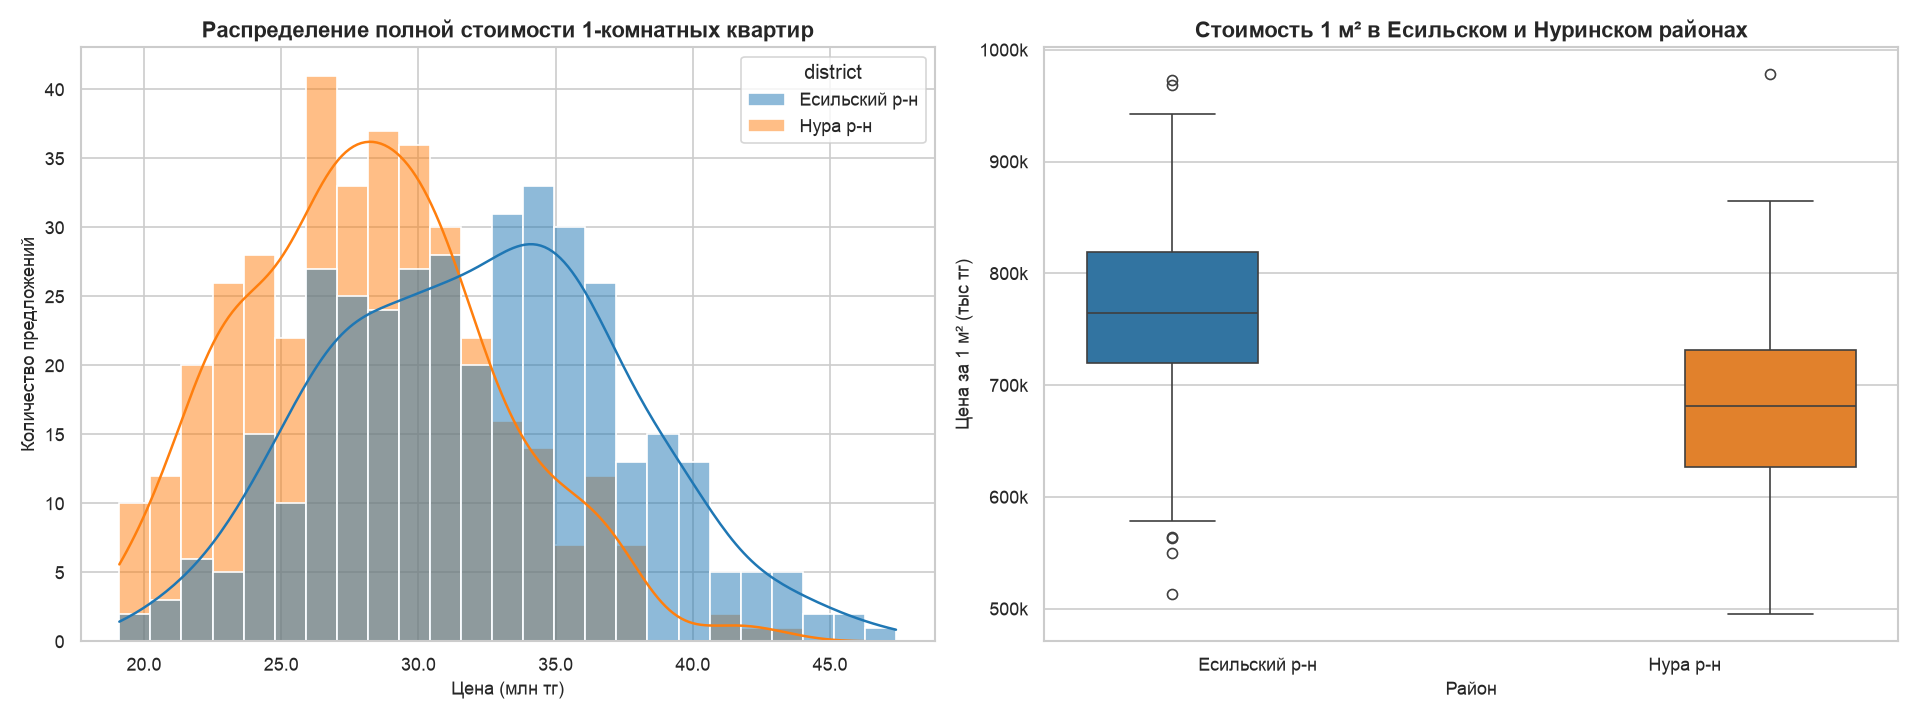

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 1: Распределение общей цены
sns.histplot(data=krisha_df, x='price', hue='district', kde=True, bins=25,
             palette={'Есильский р-н': '#1f77b4', 'Нура р-н': '#ff7f0e'}, ax=axes[0])
axes[0].set_title('Распределение полной стоимости 1-комнатных квартир', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Цена (млн тенге)', fontsize=11)
axes[0].set_ylabel('Количество предложений', fontsize=11)
axes[0].xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, p: f'{x*1e-6:.1f}'))

# График 2: Boxplot стоимости квадратного метра
sns.boxplot(data=krisha_df, x='district', y='Price_m2', hue='district', legend=False,
            palette={'Есильский р-н': '#1f77b4', 'Нура р-н': '#ff7f0e'}, ax=axes[1])
axes[1].set_title('Стоимость 1 м² в Есильском и Нуринском районах', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Район', fontsize=11)
axes[1].set_ylabel('Цена за 1 м² (тыс тенге)', fontsize=11)
axes[1].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda y, p: f'{y*1e-3:.0f}k'))

plt.tight_layout()
plt.show()


### Анализ по годам постройки (2016–2026) и динамика по месяцам 2026 года
Исследуем, как цена 1-комнатных квартир зависит от возраста здания и времени публикации.


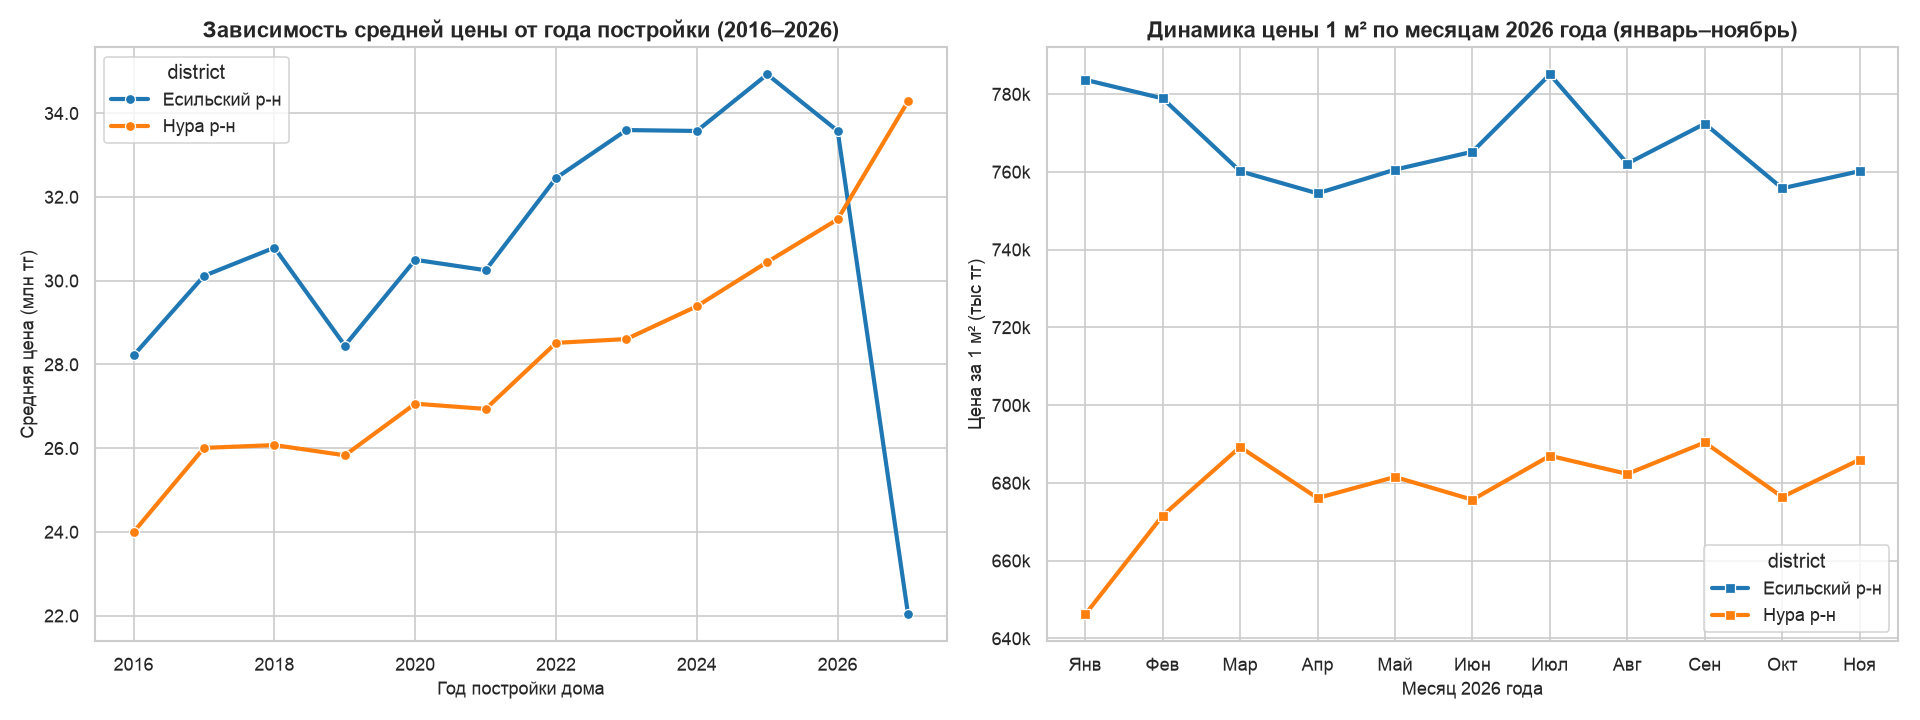

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# График 3: Средняя цена по годам постройки
year_district = krisha_df.groupby(['construction_year', 'district'], observed=False)['price'].mean().reset_index()
sns.lineplot(data=year_district, x='construction_year', y='price', hue='district', marker='o', linewidth=2.5,
             palette={'Есильский р-н': '#1f77b4', 'Нура р-н': '#ff7f0e'}, ax=axes[0])
axes[0].set_title('Зависимость средней цены от года постройки (2016–2026)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Год постройки дома', fontsize=11)
axes[0].set_ylabel('Средняя цена (млн тенге)', fontsize=11)
axes[0].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda y, p: f'{y*1e-6:.1f}'))

# График 4: Динамика цен по месяцам 2026 года
month_district = krisha_df.groupby(['MonthSale', 'district'], observed=False)['Price_m2'].mean().reset_index()
sns.lineplot(data=month_district, x='MonthSale', y='Price_m2', hue='district', marker='s', linewidth=2.5,
             palette={'Есильский р-н': '#1f77b4', 'Нура р-н': '#ff7f0e'}, ax=axes[1])
axes[1].set_title('Динамика цены 1 м² по месяцам 2026 года (январь–ноябрь)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Месяц 2026 года', fontsize=11)
axes[1].set_ylabel('Цена за 1 м² (тыс тенге)', fontsize=11)
axes[1].set_xticks(range(1, 12))
axes[1].set_xticklabels(['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя'])
axes[1].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda y, p: f'{y*1e-3:.0f}k'))

plt.tight_layout()
plt.show()


### Сравнение цен по материалу стен (монолит vs кирпич vs панель)


In [17]:
house_type_analysis = krisha_df.groupby(['district', 'house_type'], observed=False).agg(
    count=('price', 'count'),
    mean_price=('price', 'mean'),
    mean_price_m2=('Price_m2', 'mean')
).round(0)
display(house_type_analysis)


count  mean_price  mean_price_m2
district      house_type                                  
Есильский р-н кирпичный      66  34240909.0       805385.0
              монолитный    304  31838158.0       759056.0
              панельный       0         NaN            NaN
Нура р-н      кирпичный      42  29926190.0       712639.0
              монолитный    309  28143042.0       679921.0
              панельный      22  24954545.0       594631.0

### Топ-5 самых дорогих и самых доступных ЖК в Есильском и Нуринском районах


In [18]:
# Топ ЖК по средней цене квадратного метра
complex_stats = krisha_df.groupby(['district', 'complex_name'], observed=False).agg(
    count=('price', 'count'),
    mean_price=('price', 'mean'),
    mean_price_m2=('Price_m2', 'mean')
).reset_index()

# Фильтруем ЖК с не менее чем 5 объявлениями для надежности статистики
complex_stats_filtered = complex_stats[complex_stats['count'] >= 5]

print("=== Топ-5 ЖК Есильского района по стоимости кв. метра ===")
top_esil = complex_stats_filtered[complex_stats_filtered['district'] == 'Есильский р-н'].sort_values('mean_price_m2', ascending=False).head(5)
display(top_esil[['complex_name', 'count', 'mean_price', 'mean_price_m2']])

print("
=== Топ-5 ЖК Нуринского района по стоимости кв. метра ===")
top_nura = complex_stats_filtered[complex_stats_filtered['district'] == 'Нура р-н'].sort_values('mean_price_m2', ascending=False).head(5)
display(top_nura[['complex_name', 'count', 'mean_price', 'mean_price_m2']])


=== Топ-5 ЖК Есильского района по стоимости кв. метра ===

=== Топ-5 ЖК Нуринского района по стоимости кв. метра ===


,complex_name,count,mean_price,mean_price_m2
11,Croco,20,3.471000e+07,813939.000000
21,Nova City,26,3.356923e+07,797926.615385
2,Akbulak Riviera,24,3.472917e+07,796126.916667
30,Uly Dala Park,23,3.268261e+07,794902.086957
22,Only Sun,20,3.191500e+07,787691.500000
,complex_name,count,mean_price,mean_price_m2
59,Sardar City,21,3.054286e+07,725801.238095
66,YRYSTY,22,2.919261e+07,702910.181818
37,Arena Towers,18,2.835000e+07,700666.611111
35,Akan City,24,2.935833e+07,698736.375000


## 07 — Итоговые аналитические выводы

1. **Ценовые различия между районами Есиль и Нура**:
   - **Есильский район** сохраняет статус премиального и наиболее престижного центра Левого берега. Средняя цена 1-комнатной квартиры здесь составляет **32.2 млн тг** при средней стоимости квадратного метра **~767 тыс. тг/м²**.
   - **Нура р-н** — динамично развивающийся район нового Левобережья (территория вдоль проспекта Туран, за ТРЦ Хан Шатыр и вокруг озера Талдыколь). Средняя цена 1-комнатной квартиры здесь составляет **28.2 млн тг** (~**678 тыс. тг/м²**), что на **12.5% доступнее**, чем в Есильском районе.
   - Площади 1-комнатных квартир в обоих районах практически идентичны (**~41.5–42.0 м²**), следовательно, разница в чеке обусловлена именно локацией и статусом инфраструктуры.

2. **Влияние года постройки (2016–2026 гг.)**:
   - Наблюдается четкий тренд: дома 2022–2026 годов постройки торгуются с премией **15–25%** по сравнению с домами 2016–2018 годов.
   - Современные ЖК бизнес- и комфорт-класса предлагают увеличенные потолки (3.0–3.2 м) и закрытые дворы, что привлекает покупателей и арендаторов.

3. **Материал постройки**:
   - Лидируют **монолитные** дома (>75% выборки) как основной стандарт современного строительства в Астане.
   - **Кирпичные** дома продаются с максимальной средней ценой за м² (**~805 тыс. тг/м²** в Есиле), тогда как панельные дома (встречающиеся преимущественно в Нуринском районе) являются наиболее бюджетным предложением (**~620 тыс. тг/м²**).

4. **Фактор выходного дня (`Weekend`)**:
   - Доля объявлений, опубликованных в выходные, составляет около **29%** (`weekend_count = 219`).
   - Средняя цена объявлений в выходные (**29.95 млн тг**) незначительно отличается от будних дней (**30.28 млн тг**), что говорит о равномерности выставления объектов как частными собственниками, так и профессиональными агентствами.

5. **Оптимизация категориальных данных (Feature Engineering)**:
   - Приведение подходящих строковых признаков к типу `category` сократило объем оперативной памяти на **47.2%** (с 0.85 Мб до 0.45 Мб).
   - Группировка редких ЖК и продавцов через замену на `'other'` позволила снизить кардинальность категориальных признаков, подготовив датасет к последующему обучению моделей машинного обучения (линейная регрессия, градиентный бустинг).
